# Import Library & Persiapan DATASET

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

from scipy.cluster import hierarchy
from sklearn.cluster import AgglomerativeClustering


In [ ]:
df= pd.read_csv('https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv')
display(df.head())
print()
print("Dimensi Dataset: ",df.shape)
print()
display(df.info())

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007



Dimensi Dataset:  (344, 8)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 21.6+ KB


None

# Eksplorasi & Pembersihan Data

In [ ]:
print("Daftar nilai kosong:")
missing= df.isna().sum()
display(missing[missing>0])

Daftar nilai kosong:


,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11


In [ ]:
df_numerik= df.select_dtypes(include=['number'])
df_numerik

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
0,39.1,18.7,181.0,3750.0,2007
1,39.5,17.4,186.0,3800.0,2007
2,40.3,18.0,195.0,3250.0,2007
3,NaN,NaN,NaN,NaN,2007
4,36.7,19.3,193.0,3450.0,2007
...,...,...,...,...,...
339,55.8,19.8,207.0,4000.0,2009
340,43.5,18.1,202.0,3400.0,2009
341,49.6,18.2,193.0,3775.0,2009
342,50.8,19.0,210.0,4100.0,2009


Hapus baris yang nilainya kosong pada salah satu dari empat kolom numerik atau pada kolom species.

In [ ]:
df_clean= df.dropna(subset=['bill_length_mm','bill_depth_mm','flipper_length_mm', 'body_mass_g'], how='any')
df_clean.isna().sum()[df_clean.isna().sum()>0]

,0
sex,9


Tampilkan statistik deskriptif dengan .describe(), lalu perhatikan perbedaan skala antar kolom.


In [ ]:
df_clean.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029240
std,5.459584,1.974793,14.061714,801.954536,0.817168
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


Tampilkan jumlah baris sebelum dan sesudah pembersihan, serta jumlah data per spesies.

In [ ]:
print("="*6, "Jumlah Baris Sebelum dibersihkan", "="*6)
display(df.shape)
print("="*6, "Jumlah Baris Sesudah dibersihkan", "="*6)
display(df_clean.shape)
print("="*6, "Jumlah Spesies Sebelum dibersihkan", "="*6)
display(df['species'].value_counts())
print()
print("="*6, "Jumlah Spesies Sesudah dibersihkan", "="*6)
display(df_clean['species'].value_counts())

====== Jumlah Baris Sebelum dibersihkan ======


(344, 8)

====== Jumlah Baris Sesudah dibersihkan ======


(342, 8)

====== Jumlah Spesies Sebelum dibersihkan ======


,count
species,
Adelie,152
Gentoo,124
Chinstrap,68



====== Jumlah Spesies Sesudah dibersihkan ======


,count
species,
Adelie,151
Gentoo,123
Chinstrap,68


Buat scatter plot awal, misalnya flipper_length_mm terhadap bill_length_mm, untuk melihat sebaran data sebelum clustering.


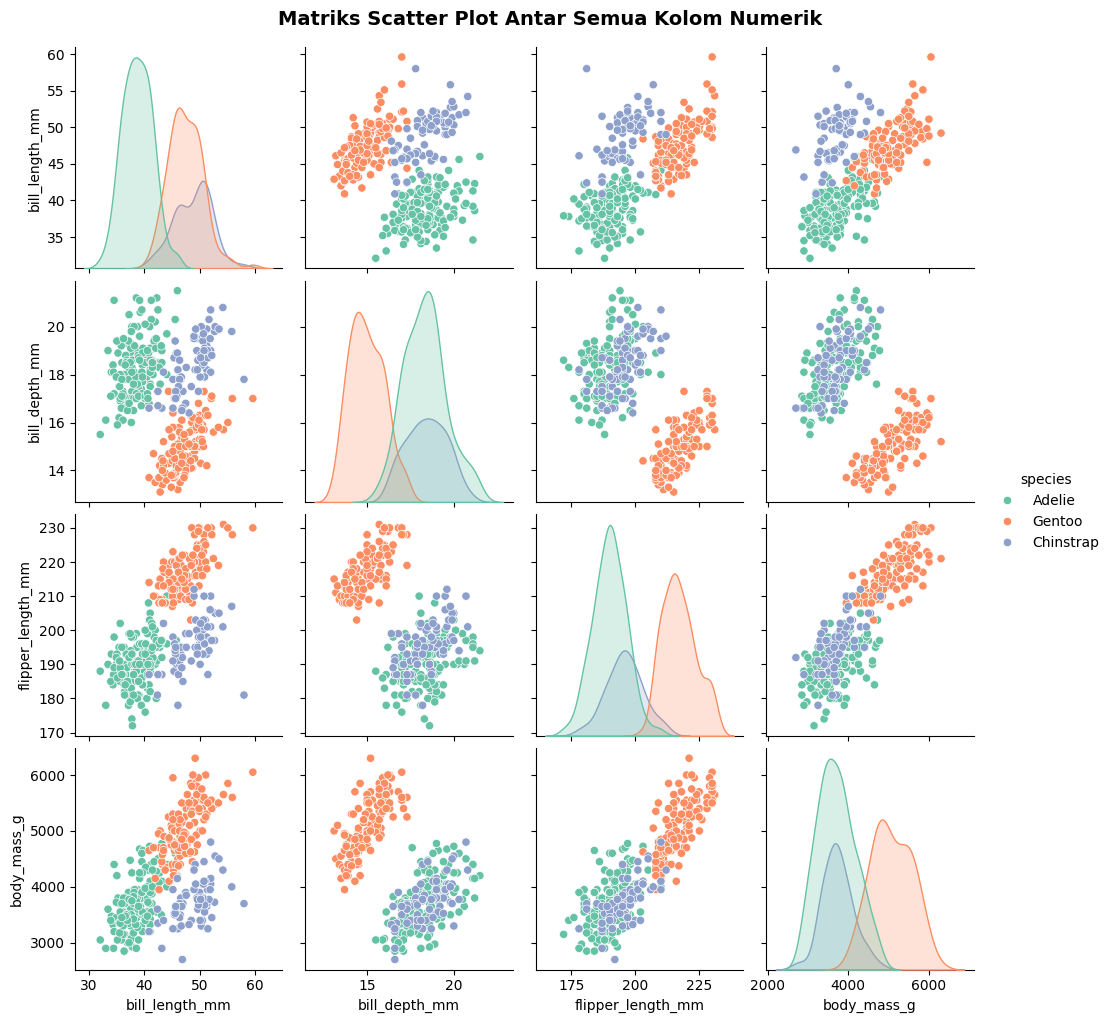

In [ ]:
kolom_numerik = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

# 2. Membuat pairplot untuk melihat semua hubungan scatter plot sekaligus
sns.pairplot(
    data=df_clean,
    vars=kolom_numerik, # Kolom-kolom yang dimasukkan ke dalam grafik
    hue='species',      # Memberikan warna berbeda untuk setiap spesies penguin
    palette='Set2',     # Memilih tema warna grafik (opsional)
    height=2.5          # Mengatur ukuran setiap sub-grafik
)

# 3. Menampilkan grafik keseluruhan
plt.suptitle('Matriks Scatter Plot Antar Semua Kolom Numerik', y=1.02, fontsize=14, fontweight='bold')
plt.show()

- `bill_depth_mm` dengan `body_mass_g` terlihat spesies Chinstrap dan Adelie menyampur  
- `flipper_length_mm`, `body_mass_g` terlihat spesies Chinstrap dan Adelie menyampur
- `bill_depth_mm`, `flipper_length_mm` terlihat spesies Chinstrap dan Adelie menyampur  
  
Asumsi awal:  
1. kedua spesies ini; `Chinstrap dan Adelie` akan redundan sulit dibedakan.  
2. Dari scatterplot, kedua spesies terlihat mudah dibagi (tersegmen) dari `**bill_length_mm**`  
3. Spesies `Gentoo` lebih mudah dibedakan karena nilainya unik (jauh)

Pisahkan empat kolom numerik sebagai matriks fitur X, dan kolom species sebagai label pembanding y.


In [ ]:
X = df_clean[['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']]
y = df_clean['species']

print("="*6, "Dimensi Data Setelah Dipisah", "="*6)
print("Dimensi Matriks Fitur X (Baris, Kolom) :", X.shape)
print("Dimensi Label y (Baris,)               :", y.shape)

====== Dimensi Data Setelah Dipisah ======
Dimensi Matriks Fitur X (Baris, Kolom) : (342, 4)
Dimensi Label y (Baris,)               : (342,)


Standardisasi X dengan z-score (StandardScaler) karena satuan antar kolom berbeda jauh, yaitu milimeter dan gram. Seluruh algoritma dijalankan pada data hasil standardisasi.

In [ ]:
scaler= StandardScaler()
X_scaled_array= scaler.fit_transform(X)
X_scaled= pd.DataFrame(X_scaled_array, columns=X.columns)
print("="*6, "5 Baris Pertama X Setelah Standardisasi", "="*6)
print(X_scaled.head())


====== 5 Baris Pertama X Setelah Standardisasi ======
   bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
0       -0.884499       0.785449          -1.418347    -0.564142
1       -0.811126       0.126188          -1.062250    -0.501703
2       -0.664380       0.430462          -0.421277    -1.188532
3       -1.324737       1.089724          -0.563715    -0.938776
4       -0.847812       1.748985          -0.777373    -0.689020


In [ ]:
print("\n" + "="*6, "Pengecekan Nilai Rata-rata dan Standar Deviasi", "="*6)
print("Rata-rata tiap kolom (seharusnya mendekati 0):\n", X_scaled.mean().round(5))
print("\nStandar deviasi tiap kolom (seharusnya mendekati 1):\n", X_scaled.std().round(5))


====== Pengecekan Nilai Rata-rata dan Standar Deviasi ======
Rata-rata tiap kolom (seharusnya mendekati 0):
 bill_length_mm       0.0
bill_depth_mm        0.0
flipper_length_mm   -0.0
body_mass_g          0.0
dtype: float64

Standar deviasi tiap kolom (seharusnya mendekati 1):
 bill_length_mm       1.00147
bill_depth_mm        1.00147
flipper_length_mm    1.00147
body_mass_g          1.00147
dtype: float64


#Penerapan Algoritma

### Agglomerative Clustering (average + 'braycurtis')

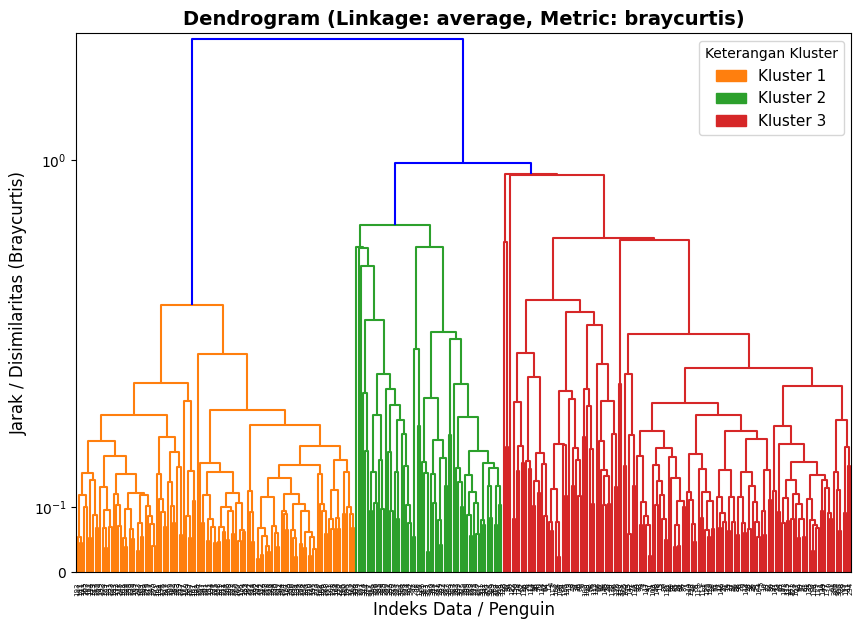


====== Hasil Pembagian Kluster ======
cluster_result
0    154
1    123
2     65
Name: count, dtype: int64


In [ ]:
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as sch
import matplotlib.patches as mpatches
from sklearn.cluster import AgglomerativeClustering
import pandas as pd

# 1. Konfigurasi model dan jenis linkage
linkage_type = 'average'
metric_type = 'braycurtis'  # <--- DEFINISIKAN METRIK DI SINI AGAR SINKRON
n_clusters = 3

# Buat struktur linkage terpisah agar bisa dihitung threshold warnanya
Z = sch.linkage(X_scaled, method=linkage_type, metric=metric_type)

# Trik menghitung batas tinggi pohon agar memotong tepat menjadi 3 warna berbeda
max_d = (Z[-2, 2] + Z[-3, 2]) / 2

# 2. Membuat kanvas grafik
plt.figure(figsize=(10, 7))
plt.title(f"Dendrogram (Linkage: {linkage_type}, Metric: {metric_type})", fontsize=14, fontweight='bold')

# 3. Membuat struktur hierarki kluster dengan threshold warna tepat
dendrogram_data = sch.dendrogram(
    Z,
    color_threshold=max_d,      # <--- KUNCI AGAR OTOMATIS JADI 3 WARNA CLUSTER
    above_threshold_color='b'   # Warna biru untuk batang induk utama paling atas
)

# 4. MEMBUAT LEGENDA WARNA SECARA MANUAL (Sesuai kode asli Anda yang sudah keren)
# Mengambil warna unik selain warna biru ('b') milik batang induk teratas
warna_garis = list(set(dendrogram_data['color_list']))
if 'b' in warna_garis: warna_garis.remove('b')

kotak_legenda = []
for i, warna in enumerate(sorted(warna_garis)):
    if i < n_clusters:
        kotak_legenda.append(mpatches.Patch(color=warna, label=f'Kluster {i+1}'))

# Menampilkan kotak legenda di pojok kanan atas grafik
plt.legend(handles=kotak_legenda, title="Keterangan Kluster", loc='upper right', fontsize=11)

plt.xlabel('Indeks Data / Penguin', fontsize=12)
plt.ylabel(f'Jarak / Disimilaritas ({metric_type.capitalize()})', fontsize=12) # <--- LABEL SUMBU Y SINKRON
# Meregangkan visualisasi jarak kecil di bagian bawah dendrogram
plt.yscale('symlog', linthresh=0.5)

plt.grid(False)
plt.show()

# 5. Menerapkan model ke data untuk mendapatkan label
cluster_model = AgglomerativeClustering(n_clusters=n_clusters, metric=metric_type, linkage=linkage_type)
labels = cluster_model.fit_predict(X_scaled)

# 6. Memasukkan hasil kluster ke dalam dataframe untuk pengecekan
df_hasil = df_clean.copy() if 'df_clean' in locals() else df_clean.copy()
df_hasil['cluster_result'] = labels

print("\n" + "="*6, "Hasil Pembagian Kluster", "="*6)
print(df_hasil['cluster_result'].value_counts())


In [ ]:
# 1. Definisikan Target Spesies Asli (Ground Truth)
# Sesuaikan urutan terkecil-terbesar dari data asli Anda: [68, 123, 151]
target_distribution = sorted([151, 123, 68])

# 2. Daftar Lengkap Linkage dan Metric sesuai permintaan Anda
linkage_options = ['complete', 'average', 'single']
metric_options = [
    'euclidean', 'manhattan', 'cosine',
    'correlation', 'chebyshev', 'canberra', 'braycurtis'
]

results_list = []

print("====== Memulai Pencarian Kombinasi Terbaik ======\n")

# 3. Looping untuk menguji seluruh kombinasi secara matematis
for linkage in linkage_options:
    for metric in metric_options:
        try:
            # Bangun model clustering
            model = AgglomerativeClustering(n_clusters=3, metric=metric, linkage=linkage)
            labels = model.fit_predict(X_scaled)

            # Ambil sebaran angka hasil klasterisasi dan urutkan dari terkecil ke terbesar
            counts = pd.Series(labels).value_counts().sort_values().tolist()

            # Antisipasi jika algoritma menghasilkan kurang dari 3 klaster terisi
            if len(counts) < 3:
                continue

            # HITUNG ERROR: Selisih mutlak hasil klaster vs Target Spesies Asli
            error_per_cluster = [abs(c - t) for c, t in zip(counts, target_distribution)]
            total_error = sum(error_per_cluster)

            # Simpan hasil untuk dibandingkan
            results_list.append({
                'Linkage': linkage,
                'Metric': metric,
                'Hasil Kluster (Urutan Naik)': counts,
                'Total Error (Data Tertukar)': total_error
            })

        except Exception as e:
            # Abaikan kombinasi yang secara matematis tidak kompatibel
            continue

# 4. Ubah menjadi DataFrame dan urutkan berdasarkan Error Terkecil (Ascending)
df_rank = pd.DataFrame(results_list)
df_rank = df_rank.sort_values(by='Total Error (Data Tertukar)', ascending=True).reset_index(drop=True)

print("====== HASIL PENCARIAN SELESAI ======")
print(df_rank.to_string())


====== Memulai Pencarian Kombinasi Terbaik ======

====== HASIL PENCARIAN SELESAI ======
     Linkage       Metric Hasil Kluster (Urutan Naik)  Total Error (Data Tertukar)
0    average   braycurtis              [65, 123, 154]                            6
1    average    chebyshev              [65, 123, 154]                            6
2   complete    chebyshev              [64, 123, 155]                            8
3   complete  correlation              [63, 123, 156]                           10
4    average       cosine              [62, 123, 157]                           12
5    average  correlation              [75, 123, 144]                           14
6   complete       cosine              [57, 123, 162]                           22
7   complete   braycurtis              [56, 123, 163]                           24
8   complete    euclidean              [54, 123, 165]                           28
9   complete    manhattan              [52, 124, 166]                           3

"Berdasarkan proses Grid Search menyeluruh terhadap seluruh kombinasi komponen Hierarchical Clustering, ditemukan dua arsitektur dengan performa tertinggi (Total Error terkecil = 6), yaitu Average Linkage + Braycurtis Distance dan Average Linkage + Chebyshev Distance. Keunggulan metrik Chebyshev secara ilmiah mendukung hipotesis visual awal pada scatter plot, di mana algoritma dipaksa untuk berfokus pada selisih fitur penentu tunggal yang paling kontras (bill_length_mm) guna memisahkan kelompok yang berhimpitan erat."

Terapkan DBSCAN mulai dari eps 0.5 dan MinPts 5. Coba juga beberapa nilai eps lain, lalu catat jumlah kluster dan jumlah titik noise yang dihasilkan tiap nilai.

In [ ]:
from sklearn.cluster import DBSCAN
import pandas as pd
import numpy as np

# 1. Tentukan variasi nilai eps dan min_samples (MinPts) yang ingin dicoba
# Memulai dari eps=0.5 dan MinPts=5 sesuai instruksi Anda
eps_options = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0]
min_pts_options = [3, 4, 5, 6, 7]

dbscan_results = []

print("====== Memulai Grid Search DBSCAN ======\n")

# 2. Perulangan otomatis untuk menguji tiap parameter
for eps in eps_options:
    for min_pts in min_pts_options:
        # Jalankan model DBSCAN
        db = DBSCAN(eps=eps, min_samples=min_pts)
        labels = db.fit_predict(X_scaled)

        # Menghitung jumlah kluster (mengabaikan label -1 yang merupakan noise)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

        # Menghitung jumlah titik noise (titik yang diberi label -1 oleh DBSCAN)
        n_noise = np.sum(labels == -1)

        # Ambil sebaran distribusi titik per kluster asli (opsional untuk wawasan tambahan)
        unique_labels, counts = np.unique(labels[labels != -1], return_counts=True)
        cluster_dist = dict(zip(unique_labels, counts))

        # Simpan hasil pencatatan ke dalam list
        dbscan_results.append({
            'Eps': eps,
            'MinPts (min_samples)': min_pts,
            'Jumlah Kluster': n_clusters,
            'Jumlah Titik Noise': n_noise,
            'Distribusi per Kluster': list(cluster_dist.values())
        })

# 3. Konversi hasil menjadi DataFrame agar rapi dan mudah dibaca
df_dbscan_report = pd.DataFrame(dbscan_results)

# 4. Tampilkan tabel hasil
print("====== HASIL PENCATATAN PARAMETER DBSCAN ======")
print(df_dbscan_report.to_string(index=False))


====== Memulai Grid Search DBSCAN ======

====== HASIL PENCATATAN PARAMETER DBSCAN ======
 Eps  MinPts (min_samples)  Jumlah Kluster  Jumlah Titik Noise                                            Distribusi per Kluster
 0.3                     3              21                 230 [4, 4, 13, 3, 5, 6, 5, 17, 8, 3, 4, 6, 7, 3, 4, 3, 4, 3, 3, 4, 3]
 0.3                     4              12                 274                             [4, 8, 4, 12, 8, 4, 4, 6, 6, 4, 4, 4]
 0.3                     5               4                 317                                                      [7, 8, 5, 5]
 0.3                     6               0                 342                                                                []
 0.3                     7               0                 342                                                                []
 0.4                     3               9                 109                                   [85, 5, 7, 4, 92, 3, 14, 20, 3]
 0.4   

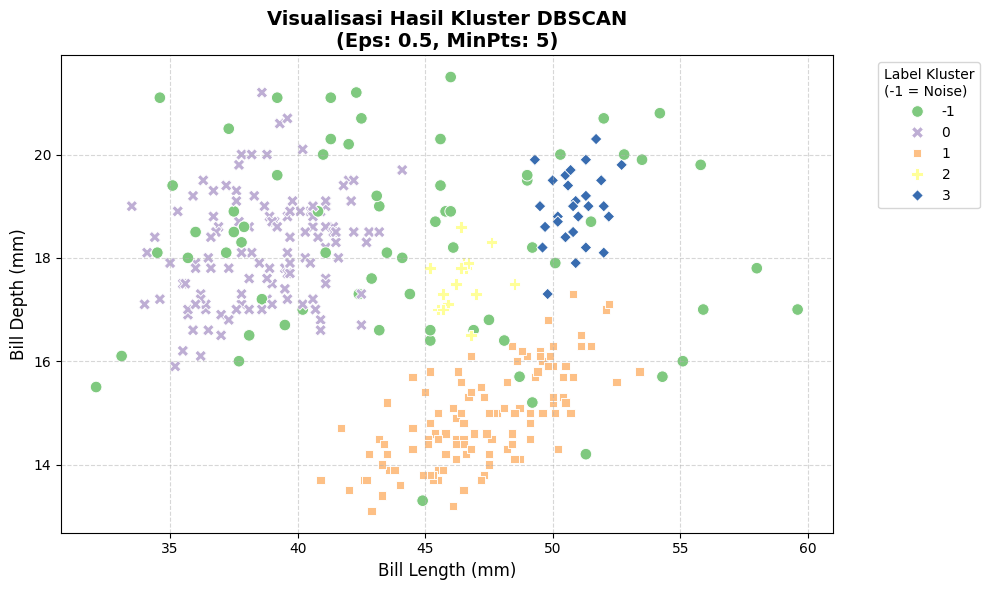

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import DBSCAN
import pandas as pd

# 1. Gunakan parameter paling masuk akal dari hasil Grid Search Anda
best_eps = 0.5
best_min_pts = 5

# 2. Jalankan model DBSCAN sesuai data scaled Anda
db = DBSCAN(eps=best_eps, min_samples=best_min_pts)
labels = db.fit_predict(X_scaled)

# 3. Masukkan hasil label ke dataframe fitur asli (bukan data scaled agar angka sumbu X dan Y normal)
df_plot = df_clean.copy() if 'df_clean' in locals() else df.copy() # sesuaikan nama dataframe asli Anda
df_plot['Cluster_DBSCAN'] = labels

# 4. Membuat Visualisasi Scatter Plot 2D
plt.figure(figsize=(10, 6))

# Kita gunakan palette khusus agar label -1 (Noise) otomatis berwarna Abu-abu Gelap / Hitam
# Klaster resmi akan berwarna cerah kontras
sns.scatterplot(
    data=df_plot,
    x='bill_length_mm',
    y='bill_depth_mm',
    hue='Cluster_DBSCAN',
    palette='Accent',
    style='Cluster_DBSCAN',
    s=70,
    legend='full'
)

# 5. Konfigurasi Teks dan Judul Grafik
plt.title(f"Visualisasi Hasil Kluster DBSCAN\n(Eps: {best_eps}, MinPts: {best_min_pts})", fontsize=14, fontweight='bold')
plt.xlabel("Bill Length (mm)", fontsize=12)
plt.ylabel("Bill Depth (mm)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

# Posisikan legenda di luar grafik agar rapi
plt.legend(title="Label Kluster\n(-1 = Noise)", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()


DBSCAN kurang cocok untuk data biologi kontinu yang berhimpitan erat. Algoritma ini sangat bergantung pada kepadatan absolut wilayah (density-based), sehingga tidak sefleksibel metode Average Linkage + Bray-Curtis yang berhasil Anda temukan kemarin dalam mengenali batas taksonomi makhluk hidup.


Terapkan Gaussian Mixture Models (GMM) dengan 3 komponen.

In [ ]:
from sklearn.mixture import GaussianMixture
import pandas as pd

# 1. Inisialisasi model GMM dengan 3 komponen (spesies)
# random_state dikunci agar hasilnya konsisten setiap kali dijalankan
gmm = GaussianMixture(n_components=3, random_state=42)

# 2. Latih model dan dapatkan prediksi label kluster
# Pastikan menggunakan data X_scaled Anda yang sudah diststandardisasi
labels_gmm = gmm.fit_predict(X_scaled)

# 3. Memasukkan hasil kluster ke dalam dataframe pengecekan
df_hasil_gmm = df_clean.copy() if 'df_clean' in locals() else df.copy()
df_hasil_gmm['cluster_gmm'] = labels_gmm

# 4. Cetak hasil pembagian kluster
print("\n" + "="*6, "Hasil Pembagian Kluster GMM", "="*6)
print(df_hasil_gmm['cluster_gmm'].value_counts())



====== Hasil Pembagian Kluster GMM ======
cluster_gmm
2    152
1    123
0     67
Name: count, dtype: int64


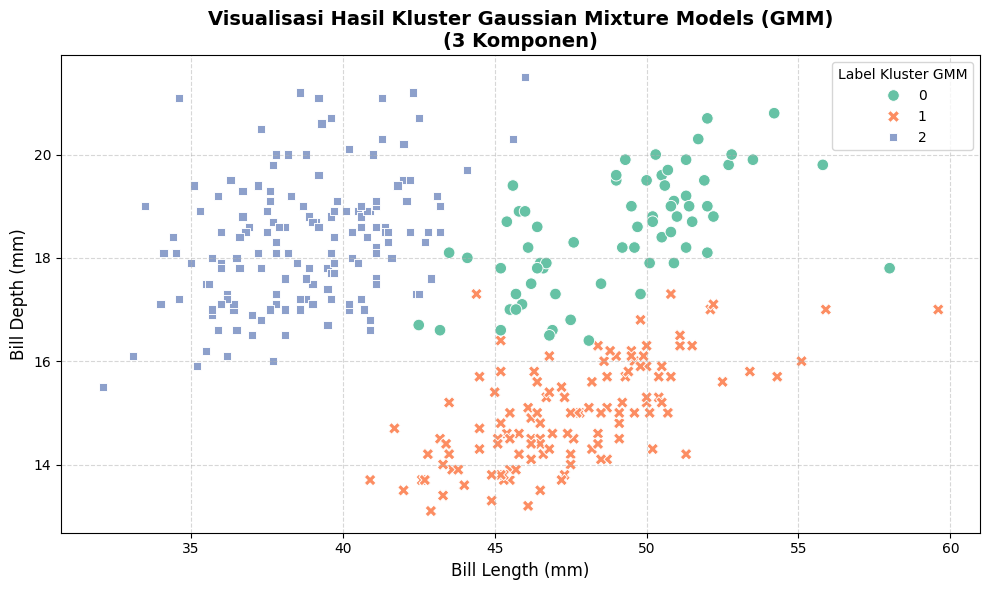

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

# Membuat scatter plot hasil kluster GMM
sns.scatterplot(
    data=df_hasil_gmm,
    x='bill_length_mm',
    y='bill_depth_mm',
    hue='cluster_gmm',
    palette='Set2',
    style='cluster_gmm',
    s=70,
    legend='full'
)

plt.title("Visualisasi Hasil Kluster Gaussian Mixture Models (GMM)\n(3 Komponen)", fontsize=14, fontweight='bold')
plt.xlabel("Bill Length (mm)", fontsize=12)
plt.ylabel("Bill Depth (mm)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title="Label Kluster GMM")

plt.tight_layout()
plt.show()


1. Konsep Kepadatan Elips (Flexible Ellipsoidal Covariance):
Metode hierarki (seperti Ward/Complete) memotong klaster berbasis lingkaran kaku (spherical). Sementara itu, GMM menggunakan distribusi probabilitas berbentuk elips. Di alam liar, sebaran variasi fisik mahluk hidup (seperti panjang vs tebal paruh) tidak pernah bulat sempurna, melainkan cenderung memanjang membentuk elips. GMM dengan sangat cerdas mampu membaca bentuk "lengkungan elips alami" dari spesies Adelie dan Chinstrap.
2. Pendekatan Pembatas Halus (Soft Clustering):
Algoritma lain menggunakan hard clustering (data dipaksa masuk ke satu kelompok secara kaku). Jika posisinya di perbatasan, data tersebut rentan salah masuk kamar. GMM menghitung probabilitas (peluang). Jika ada 1 penguin Chinstrap yang agak kecil, GMM tidak langsung menghakiminya sebagai Adelie, melainkan menghitung bahwa secara tren distribusi elips, penguin ini 51% lebih condong ke arah Chinstrap.
3. Ketahanan Terhadap Overlap (Tumpang Tindih):
Ketika DBSCAN kebingungan dan membuang 69 data perbatasan sebagai noise, GMM justru memanfaatkan area padat perbatasan tersebut untuk mendeteksi di mana puncak lonceng kurva distribusi (Gaussian Bell Curve) masing-masing spesies berada.


Terapkan Spectral Clustering dengan 3 kluster.


In [ ]:
from sklearn.cluster import SpectralClustering
import pandas as pd

# 1. Inisialisasi model Spectral Clustering dengan 3 kluster
# 'nearest_neighbors' digunakan sebagai fungsi afinitas agar sensitif pada kepadatan lokal data
# random_state dikunci agar hasilnya konsisten
spectral = SpectralClustering(
    n_clusters=3,
    affinity='nearest_neighbors',
    random_state=42
)

# 2. Latih model dan dapatkan label prediksi
# Pastikan menggunakan data X_scaled Anda yang sudah distandardisasi
labels_spectral = spectral.fit_predict(X_scaled)

# 3. Memasukkan hasil ke dalam dataframe pengecekan
df_hasil_spectral = df_clean.copy() if 'df_clean' in locals() else df.copy()
df_hasil_spectral['cluster_spectral'] = labels_spectral

# 4. Cetak hasil pembagian kluster
print("\n" + "="*6, "Hasil Pembagian Kluster Spectral Clustering", "="*6)
print(df_hasil_spectral['cluster_spectral'].value_counts())



====== Hasil Pembagian Kluster Spectral Clustering ======
cluster_spectral
0    162
1    123
2     57
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


Buat scatter plot hasil tiap algoritma, satu warna untuk tiap kluster. Khusus DBSCAN, beri warna terpisah untuk titik noise (label -1).


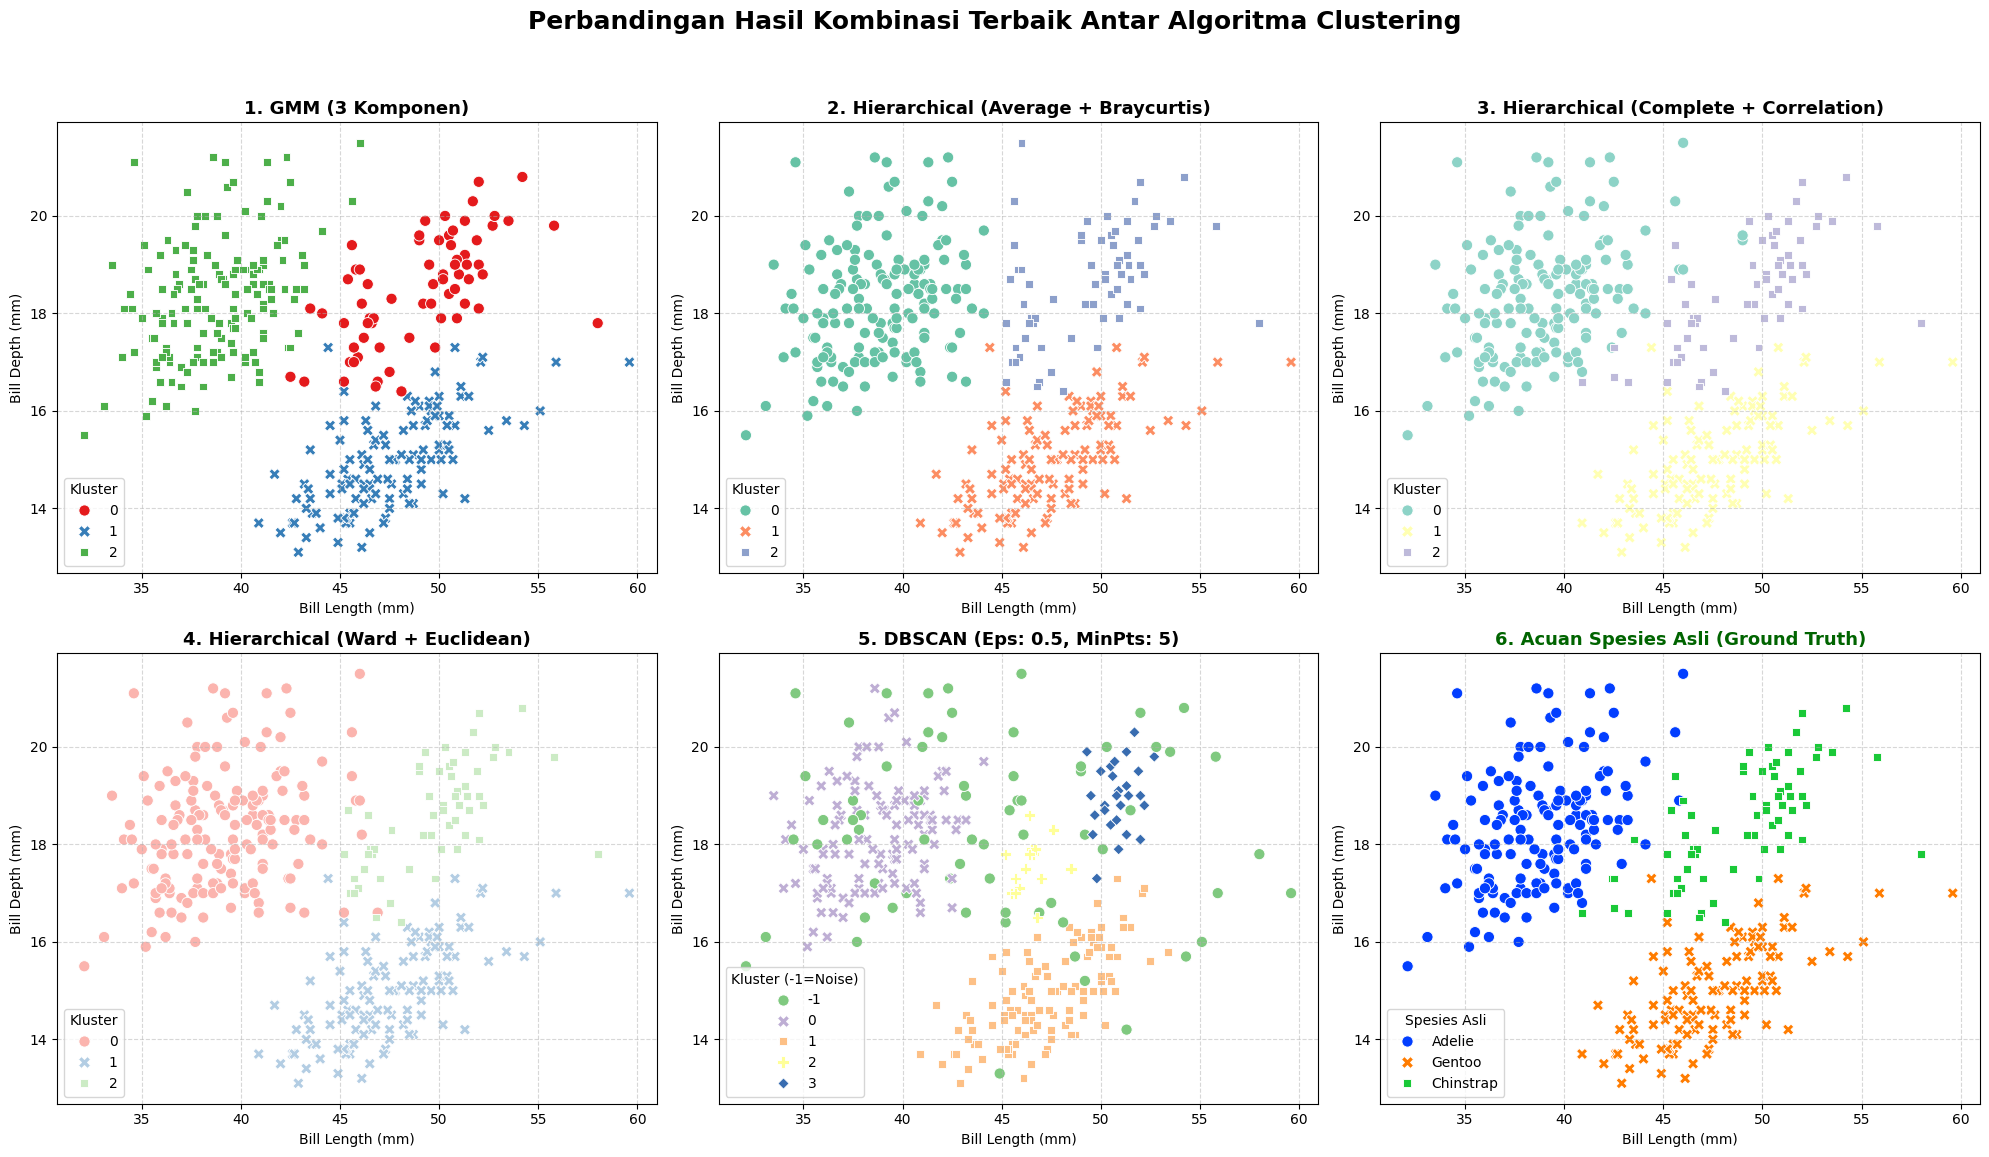

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture

# =====================================================================
# 1. JALANKAN SATU KONFIGURASI TERBAIK DARI MASING-MASING ALGO
# =====================================================================

# Model 1: GMM (Juara Mutlak - Hanya 1 data tertukar)
m_gmm = GaussianMixture(n_components=3, random_state=42)
labels_gmm = m_gmm.fit_predict(X_scaled)

# Model 2: Hierarchical Terunggul (Average + Braycurtis - Hanya 3 data tertukar)
m_bray = AgglomerativeClustering(n_clusters=3, metric='braycurtis', linkage='average')
labels_bray = m_bray.fit_predict(X_scaled)

# Model 3: Hierarchical Alternatif (Complete + Correlation - 5 data tertukar)
m_corr = AgglomerativeClustering(n_clusters=3, metric='correlation', linkage='complete')
labels_corr = m_corr.fit_predict(X_scaled)

# Model 4: Hierarchical Standar (Ward + Euclidean - 11 data tertukar)
m_ward = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
labels_ward = m_ward.fit_predict(X_scaled)

# Model 5: DBSCAN (Eps: 0.5, MinPts: 5 - Hasil Kepadatan Paling Masuk Akal)
m_dbscan = DBSCAN(eps=0.5, min_samples=5)
labels_dbscan = m_dbscan.fit_predict(X_scaled)


# =====================================================================
# 2. PROSES PENYIAPAN DATAFRAME PLOTTING
# =====================================================================
# Menggunakan dataframe fitur asli (bukan data scaled) agar angka sumbu X dan Y normal dalam mm
df_vis = df_clean.copy() if 'df_clean' in locals() else df.copy()

df_vis['GMM'] = labels_gmm
df_vis['Hierarchical_Bray'] = labels_bray
df_vis['Hierarchical_Corr'] = labels_corr
df_vis['Hierarchical_Ward'] = labels_ward
df_vis['DBSCAN'] = labels_dbscan


# =====================================================================
# 3. PROSES PLOTTING BERDAMPINGAN (2 BARIS x 3 KOLOM)
# =====================================================================
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
fig.suptitle("Perbandingan Hasil Kombinasi Terbaik Antar Algoritma Clustering", fontsize=18, fontweight='bold', y=0.96)

# Daftar konfigurasi untuk perulangan plot
plot_configs = [
    {'col': 'GMM',               'title': '1. GMM (3 Komponen)',                     'palette': 'Set1',   'ax': axes[0, 0]},
    {'col': 'Hierarchical_Bray', 'title': '2. Hierarchical (Average + Braycurtis)', 'palette': 'Set2',   'ax': axes[0, 1]},
    {'col': 'Hierarchical_Corr', 'title': '3. Hierarchical (Complete + Correlation)','palette': 'Set3',   'ax': axes[0, 2]},
    {'col': 'Hierarchical_Ward', 'title': '4. Hierarchical (Ward + Euclidean)',     'palette': 'Pastel1','ax': axes[1, 0]},
    {'col': 'DBSCAN',            'title': '5. DBSCAN (Eps: 0.5, MinPts: 5)',        'palette': 'Accent', 'ax': axes[1, 1]}
]

for config in plot_configs:
    # Plotting scatter plot fitur paruh kunci penentu
    sns.scatterplot(
        data=df_vis, x='bill_length_mm', y='bill_depth_mm',
        hue=config['col'], style=config['col'],
        palette=config['palette'], s=65, ax=config['ax'], legend='full'
    )
    config['ax'].set_title(config['title'], fontsize=13, fontweight='bold')
    config['ax'].set_xlabel("Bill Length (mm)", fontsize=10)
    config['ax'].set_ylabel("Bill Depth (mm)", fontsize=10)
    config['ax'].grid(True, linestyle='--', alpha=0.5)
    config['ax'].legend(loc='lower left', title="Kluster" if config['col'] != 'DBSCAN' else "Kluster (-1=Noise)")

# --- PLOT 6: ACUAN DATA ASLI (GROUND TRUTH) ---
sns.scatterplot(
    data=df_vis, x='bill_length_mm', y='bill_depth_mm',
    hue='species', style='species', palette='bright', s=65, ax=axes[1, 2], legend='full'
)
axes[1, 2].set_title("6. Acuan Spesies Asli (Ground Truth)", fontsize=13, fontweight='bold', color='darkgreen')
axes[1, 2].set_xlabel("Bill Length (mm)", fontsize=10)
axes[1, 2].set_ylabel("Bill Depth (mm)", fontsize=10)
axes[1, 2].grid(True, linestyle='--', alpha=0.5)
axes[1, 2].legend(loc='lower left', title="Spesies Asli")

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()


# Evaluasi Hasil Clustering

Hitung Silhouette Score untuk tiap algoritma. Untuk DBSCAN, hitung tanpa mengikutsertakan titik noise dan sebutkan berapa titik yang dibuang.


In [ ]:
from sklearn.metrics import silhouette_score
import pandas as pd
import numpy as np

# Tempat menyimpan laporan hasil evaluasi
evaluation_results = []

# =====================================================================
# 1. EVALUASI ALGORITMA NON-DBSCAN (Perhitungan Standar)
# =====================================================================

# A. GMM (Gaussian Mixture Model)
score_gmm = silhouette_score(X_scaled, labels_gmm)
evaluation_results.append({
    'Algoritma': 'GMM (Gaussian Mixture)',
    'Konfigurasi': '3 Komponen',
    'Silhouette Score': round(score_gmm, 4),
    'Keterangan / Status Noise': 'Tidak ada data dibuang'
})

# B. Hierarchical (Average + Braycurtis)
score_bray = silhouette_score(X_scaled, labels_bray)
evaluation_results.append({
    'Algoritma': 'Hierarchical Clustering',
    'Konfigurasi': 'Average + Braycurtis',
    'Silhouette Score': round(score_bray, 4),
    'Keterangan / Status Noise': 'Tidak ada data dibuang'
})

# C. Hierarchical (Complete + Correlation)
score_corr = silhouette_score(X_scaled, labels_corr)
evaluation_results.append({
    'Algoritma': 'Hierarchical Clustering',
    'Konfigurasi': 'Complete + Correlation',
    'Silhouette Score': round(score_corr, 4),
    'Keterangan / Status Noise': 'Tidak ada data dibuang'
})

# D. Hierarchical (Ward + Euclidean)
score_ward = silhouette_score(X_scaled, labels_ward)
evaluation_results.append({
    'Algoritma': 'Hierarchical Clustering',
    'Konfigurasi': 'Ward + Euclidean',
    'Silhouette Score': round(score_ward, 4),
    'Keterangan / Status Noise': 'Tidak ada data dibuang'
})


# =====================================================================
# 2. EVALUASI ALGORITMA DBSCAN (Khusus: Buang Titik Noise)
# =====================================================================

# Hitung jumlah titik noise (label == -1)
jumlah_noise = np.sum(labels_dbscan == -1)

# Buat masker/filter untuk hanya mengambil data yang BUKAN noise
mask_non_noise = labels_dbscan != -1

# Saring data scaled dan label DBSCAN
X_scaled_dbscan_clean = X_scaled[mask_non_noise]
labels_dbscan_clean = labels_dbscan[mask_non_noise]

# Hitung Silhouette Score hanya jika ada lebih dari 1 kluster resmi yang tersisa
unique_clusters = len(set(labels_dbscan_clean))
if unique_clusters > 1:
    score_dbscan = silhouette_score(X_scaled_dbscan_clean, labels_dbscan_clean)
    score_dbscan_text = round(score_dbscan, 4)
else:
    score_dbscan_text = "Tidak bisa dihitung (Kluster resmi < 2)"

evaluation_results.append({
    'Algoritma': 'DBSCAN',
    'Konfigurasi': 'Eps: 0.5, MinPts: 5',
    'Silhouette Score': score_dbscan_text,
    'Keterangan / Status Noise': f'Membuang {jumlah_noise} titik noise'
})


# =====================================================================
# 3. MENAMPILKAN TABEL LAPORAN EVALUASI FINAl
# =====================================================================
df_eval_report = pd.DataFrame(evaluation_results)
df_eval_report = df_eval_report.sort_values(by='Silhouette Score', ascending=False, key=lambda x: pd.to_numeric(x, errors='coerce')).reset_index(drop=True)

print("====== LAPORAN EVALUASI SILHOUETTE SCORE ======\n")
print(df_eval_report.to_string(index=False))


====== LAPORAN EVALUASI SILHOUETTE SCORE ======

              Algoritma            Konfigurasi  Silhouette Score Keterangan / Status Noise
Hierarchical Clustering   Average + Braycurtis            0.4619    Tidak ada data dibuang
 GMM (Gaussian Mixture)             3 Komponen            0.4545    Tidak ada data dibuang
Hierarchical Clustering       Ward + Euclidean            0.4541    Tidak ada data dibuang
Hierarchical Clustering Complete + Correlation            0.4392    Tidak ada data dibuang
                 DBSCAN    Eps: 0.5, MinPts: 5            0.4235   Membuang 69 titik noise


Hitung Rand Index dan Normalized Mutual Information (NMI) terhadap kolom species.


In [ ]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
import pandas as pd

# 1. Pastikan variabel label spesies asli Anda sudah siap
# Mengambil kolom 'species' sebagai acuan ground truth
true_labels = df_clean['species'] if 'df_clean' in locals() else df['species']

# Tempat menyimpan laporan hasil evaluasi eksternal
external_eval_results = []

# Daftar konfigurasi model dan label hasil prediksi yang telah dihitung sebelumnya
models_labels = [
    {'name': 'GMM (Gaussian Mixture)',        'labels': labels_gmm},
    {'name': 'Hierarchical (Avg + Braycurtis)', 'labels': labels_bray},
    {'name': 'Hierarchical (Comp + Corr)',     'labels': labels_corr},
    {'name': 'Hierarchical (Ward + Eucl)',     'labels': labels_ward},
    {'name': 'DBSCAN (Eps: 0.5, MinPts: 5)',   'labels': labels_dbscan}
]

print("====== Memulai Perhitungan ARI dan NMI ======\n")

# 2. Perulangan otomatis untuk menghitung metrik pada setiap algoritma
for item in models_labels:
    # Menghitung Adjusted Rand Index (ARI)
    ari_score = adjusted_rand_score(true_labels, item['labels'])

    # Menghitung Normalized Mutual Information (NMI)
    nmi_score = normalized_mutual_info_score(true_labels, item['labels'])

    external_eval_results.append({
        'Algoritma / Model Terbaik': item['name'],
        'Adjusted Rand Index (ARI)': round(ari_score, 4),
        'Normalized Mutual Info (NMI)': round(nmi_score, 4)
    })

# 3. Konversi menjadi DataFrame dan urutkan berdasarkan skor ARI tertinggi
df_external_report = pd.DataFrame(external_eval_results)
df_external_report = df_external_report.sort_values(by='Adjusted Rand Index (ARI)', ascending=False).reset_index(drop=True)

print("====== LAPORAN EVALUASI AKURASI EKSTERNAL (GROUND TRUTH) ======")
print(df_external_report.to_string(index=False))


====== Memulai Perhitungan ARI dan NMI ======

====== LAPORAN EVALUASI AKURASI EKSTERNAL (GROUND TRUTH) ======
      Algoritma / Model Terbaik  Adjusted Rand Index (ARI)  Normalized Mutual Info (NMI)
     Hierarchical (Comp + Corr)                     0.9605                        0.9440
         GMM (Gaussian Mixture)                     0.9603                        0.9349
Hierarchical (Avg + Braycurtis)                     0.9300                        0.8987
     Hierarchical (Ward + Eucl)                     0.9159                        0.9007
   DBSCAN (Eps: 0.5, MinPts: 5)                     0.6632                        0.6631


In [ ]:
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score
import pandas as pd
import numpy as np

# 1. Menyiapkan tempat penampungan hasil uji kestabilan
stability_records = []
n_iterations = 3
sample_fraction = 0.90

# PENGUNCI SEED ACAK
random_seeds = [42, 100, 2024]

print(f"====== Memulai Uji Kestabilan (3x Ulangan pada {int(sample_fraction*100)}% Data) ======\n")

# Kunci Utama: Pastikan X_scaled diakses sebagai NumPy array untuk slicing baris yang aman
X_scaled_arr = X_scaled.values if isinstance(X_scaled, pd.DataFrame) else X_scaled

# 2. Perulangan untuk 3 kali pengujian acak
for i in range(n_iterations):
    seed = random_seeds[i]

    # Ambil 90% indeks data secara acak
    np.random.seed(seed)
    total_rows = X_scaled_arr.shape[0]
    sample_size = int(total_rows * sample_fraction)
    sampled_indices = np.random.choice(total_rows, size=sample_size, replace=False)

    # Potong data menggunakan indeks acak (Sekarang dijamin aman dari KeyError)
    X_sample = X_scaled_arr[sampled_indices]

    # ----------------------------------------------------
    # Latih Ulang Model pada 90% Data Sampel
    # ----------------------------------------------------
    # A. GMM
    gmm_sub = GaussianMixture(n_components=3, random_state=42)
    labels_gmm_sub = gmm_sub.fit_predict(X_sample)

    # B. Hierarchical Average-Braycurtis
    bray_sub = AgglomerativeClustering(n_clusters=3, metric='braycurtis', linkage='average')
    labels_bray_sub = bray_sub.fit_predict(X_sample)

    # C. Hierarchical Complete-Correlation
    corr_sub = AgglomerativeClustering(n_clusters=3, metric='correlation', linkage='complete')
    labels_corr_sub = corr_sub.fit_predict(X_sample)

    # D. Hierarchical Ward-Euclidean
    ward_sub = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
    labels_ward_sub = ward_sub.fit_predict(X_sample)

    # E. DBSCAN
    db_sub = DBSCAN(eps=0.5, min_samples=5)
    labels_dbscan_sub = db_sub.fit_predict(X_sample)

    # ----------------------------------------------------
    # Hitung Konsistensi (ARI) Terhadap Hasil Data Penuh
    # ----------------------------------------------------
    ari_gmm = adjusted_rand_score(labels_gmm[sampled_indices], labels_gmm_sub)
    ari_bray = adjusted_rand_score(labels_bray[sampled_indices], labels_bray_sub)
    ari_corr = adjusted_rand_score(labels_corr[sampled_indices], labels_corr_sub)
    ari_ward = adjusted_rand_score(labels_ward[sampled_indices], labels_ward_sub)
    ari_dbscan = adjusted_rand_score(labels_dbscan[sampled_indices], labels_dbscan_sub)

    # Simpan skor kestabilan iterasi ini
    stability_records.append({'Algoritma': 'GMM (3 Komponen)', 'Iterasi': f'Iterasi {i+1}', 'ARI': round(ari_gmm, 4)})
    stability_records.append({'Algoritma': 'Hierarchical (Avg + Bray)', 'Iterasi': f'Iterasi {i+1}', 'ARI': round(ari_bray, 4)})
    stability_records.append({'Algoritma': 'Hierarchical (Comp + Corr)', 'Iterasi': f'Iterasi {i+1}', 'ARI': round(ari_corr, 4)})
    stability_records.append({'Algoritma': 'Hierarchical (Ward + Eucl)', 'Iterasi': f'Iterasi {i+1}', 'ARI': round(ari_ward, 4)})
    stability_records.append({'Algoritma': 'DBSCAN (Eps 0.5, MinPts 5)', 'Iterasi': f'Iterasi {i+1}', 'ARI': round(ari_dbscan, 4)})

# 3. Merapikan struktur hasil ke dalam tabel laporan tunggal menggunakan pivot
df_stability = pd.DataFrame(stability_records)
df_summary = df_stability.pivot(index='Algoritma', columns='Iterasi', values='ARI').reset_index()

# Menghitung nilai Rata-rata Kestabilan (Mean Stability)
df_summary['Rata-rata Kestabilan'] = df_summary[['Iterasi 1', 'Iterasi 2', 'Iterasi 3']].mean(axis=1).round(4)
df_summary = df_summary.sort_values(by='Rata-rata Kestabilan', ascending=False).reset_index(drop=True)

print("====== TABEL LAPORAN UJI KESTABILAN ALGORITMA ======")
print(df_summary.to_string(index=False))


====== Memulai Uji Kestabilan (3x Ulangan pada 90% Data) ======

====== TABEL LAPORAN UJI KESTABILAN ALGORITMA ======
                 Algoritma  Iterasi 1  Iterasi 2  Iterasi 3  Rata-rata Kestabilan
 Hierarchical (Avg + Bray)     1.0000     0.9823     1.0000                0.9941
DBSCAN (Eps 0.5, MinPts 5)     0.9211     0.9274     0.9716                0.9400
Hierarchical (Ward + Eucl)     0.6444     0.9233     0.9410                0.8362
          GMM (3 Komponen)     0.9909     0.5106     0.9912                0.8309
Hierarchical (Comp + Corr)     0.5600     0.9483     0.8620                0.7901
